# 01 · Data Understanding & Experimental Analysis

**Project:** Marketing Incrementality & Uplift Optimization · **Dataset:** Hillstrom MineThatData E-Mail Analytics Challenge (2008)

This notebook answers the first research question, *what is the average causal effect of each e-mail campaign?*, and checks that the experiment is valid enough to support everything that follows.

| Step | Question | Method |
|---|---|---|
| 1 | Is the data what we think it is? | Schema contract, quality checks |
| 2 | Was randomization implemented correctly? | Sample-ratio-mismatch test, covariate balance (SMD), assignment classifier |
| 3 | What did each campaign do on average? | Difference in means (Welch), bootstrap, randomization inference, Lin regression adjustment, Holm correction |
| 4 | How much precision do we have? | Minimum detectable effect |
| 5 | Is there visible heterogeneity worth modelling? | Descriptive segment-level effects with multiplicity control |

> **Estimand.** For outcome $Y$ and campaign $k$: $ATE_k = E[Y(k) - Y(0)]$, where $Y(0)$ is the outcome without e-mail. Because assignment was randomized, the difference in group means is unbiased for $ATE_k$.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

from src import config, data, inference, plotting as P

P.use_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 140)
config.ARTIFACTS_DIR.mkdir(exist_ok=True)

## 1 · Data provenance and contract

The raw file is the original challenge CSV, read without modification. `data.load_raw()` enforces a data contract and **fails loudly** if any check is violated:

* all 12 documented columns are present, with no missing values;
* treatment labels are exactly `{No E-Mail, Mens E-Mail, Womens E-Mail}`;
* binary columns are 0/1, `recency` ∈ 1..12, spend and history are non-negative;
* logical consistency: no spend without a conversion, no conversion without a visit.

In [2]:
path = data.find_data_file()
df = data.load_raw(path)
print(f"Source file : {path.relative_to(ROOT)}")
print(f"Shape       : {df.shape[0]:,} customers x {df.shape[1]} columns")
df.head()

Source file : Data\Kevin_Hillstrom_MineThatData.csv
Shape       : 64,000 customers x 12 columns


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
customer_id,,,,,,,,,,,,
0,10,2) $100 - $200,142.4400,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0000
1,6,3) $200 - $350,329.0800,1,1,Rural,1,Web,No E-Mail,0,0,0.0000
2,7,2) $100 - $200,180.6500,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0000
3,9,5) $500 - $750,675.8300,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0000
4,2,1) $0 - $100,45.3400,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0000


In [3]:
dictionary = pd.DataFrame([
    ("recency", "pre-treatment", "Months since last purchase (1-12)"),
    ("history_segment", "pre-treatment", "Binned past-year spend (derived from history)"),
    ("history", "pre-treatment", "Dollar value spent in the past year"),
    ("mens", "pre-treatment", "1 = bought men's merchandise in the past year"),
    ("womens", "pre-treatment", "1 = bought women's merchandise in the past year"),
    ("zip_code", "pre-treatment", "Urban / Surburban (sic) / Rural"),
    ("newbie", "pre-treatment", "1 = new customer in the past 12 months"),
    ("channel", "pre-treatment", "Channels purchased from in the past year"),
    ("segment", "TREATMENT", "Randomized: Mens E-Mail / Womens E-Mail / No E-Mail"),
    ("visit", "OUTCOME", "Visited the website within 2 weeks of the e-mail"),
    ("conversion", "OUTCOME", "Purchased within 2 weeks"),
    ("spend", "OUTCOME", "Dollars spent within 2 weeks"),
], columns=["column", "role", "meaning"]).set_index("column")
dictionary["dtype"] = df.dtypes.astype(str)
dictionary["n_unique"] = df.nunique()
dictionary

,role,meaning,dtype,n_unique
column,,,,
recency,pre-treatment,Months since last purchase (1-12),int64,12
history_segment,pre-treatment,Binned past-year spend (derived from history),str,7
history,pre-treatment,Dollar value spent in the past year,float64,34833
mens,pre-treatment,1 = bought men's merchandise in the past year,int64,2
womens,pre-treatment,1 = bought women's merchandise in the past year,int64,2
zip_code,pre-treatment,Urban / Surburban (sic) / Rural,str,3
newbie,pre-treatment,1 = new customer in the past 12 months,int64,2
channel,pre-treatment,Channels purchased from in the past year,str,3
segment,TREATMENT,Randomized: Mens E-Mail / Womens E-Mail / No E...,str,3


**Leakage rule.** Only the eight pre-treatment columns may be used as model features. `visit`, `conversion` and `spend` are measured *after* the e-mail and are outcomes only. `data.build_features()` asserts this, and a unit test (`tests/test_data.py`) guards it.

## 2 · Data quality

In [4]:
quality = pd.DataFrame({
    "missing": df.isna().sum(),
    "min": df.select_dtypes("number").min(),
    "max": df.select_dtypes("number").max(),
    "mean": df.select_dtypes("number").mean(),
})
display(quality)

n_dup = df.duplicated().sum()
n_dup_x = df.duplicated(subset=data.PRE_TREATMENT).sum()
print(f"Exact duplicate rows               : {n_dup:,} ({n_dup / len(df):.1%}); "
      f"{(df[df.duplicated()].visit == 0).mean():.0%} of them did not visit")
print(f"Duplicate pre-treatment profiles   : {n_dup_x:,} ({n_dup_x / len(df):.1%})")
print(f"Buyers                             : {df.conversion.sum():,} ({df.conversion.mean():.2%})")
print(f"Spend > 0 among buyers             : {(df.loc[df.conversion == 1, 'spend'] > 0).mean():.1%}")

,missing,min,max,mean
channel,0,NaN,NaN,NaN
conversion,0,0.0000,1.0000,0.0090
history,0,29.9900,"3,345.9300",242.0857
history_segment,0,NaN,NaN,NaN
mens,0,0.0000,1.0000,0.5510
newbie,0,0.0000,1.0000,0.5022
recency,0,1.0000,12.0000,5.7637
segment,0,NaN,NaN,NaN
spend,0,0.0000,499.0000,1.0509
visit,0,0.0000,1.0000,0.1468


Exact duplicate rows               : 6,562 (10.3%); 94% of them did not visit
Duplicate pre-treatment profiles   : 7,791 (12.2%)
Buyers                             : 578 (0.90%)
Spend > 0 among buyers             : 100.0%


**Duplicates are kept.** The file has no customer identifier, and the features are coarse (several binary flags, a 12-level recency and a two-decimal `history`). Duplicated rows are overwhelmingly non-visitors with identical coarse profiles, which is expected at this scale. Dropping them would change the randomized sample and bias arm sizes, so every row is treated as a distinct customer.

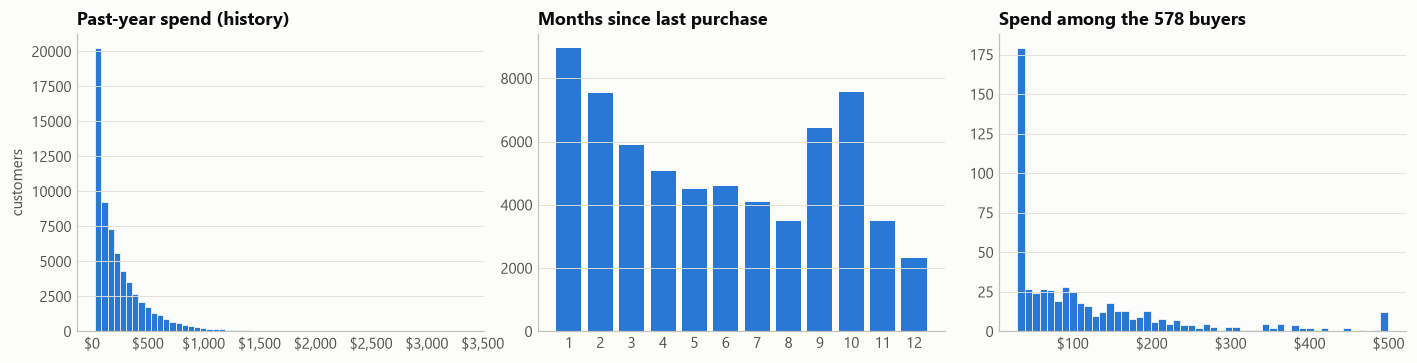

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].hist(df["history"], bins=60, color=P.BLUE, edgecolor=P.SURFACE, linewidth=0.5)
axes[0].set_title("Past-year spend (history)")
P.dollar(axes[0], "x", 0); axes[0].set_ylabel("customers")
rec = df["recency"].value_counts().sort_index()
axes[1].bar(rec.index, rec.values, color=P.BLUE, width=0.8)
axes[1].set_title("Months since last purchase"); axes[1].set_xticks(range(1, 13))
buy = df.loc[df.spend > 0, "spend"]
axes[2].hist(buy, bins=50, color=P.BLUE, edgecolor=P.SURFACE, linewidth=0.5)
axes[2].set_title(f"Spend among the {len(buy):,} buyers")
P.dollar(axes[2], "x", 0)
fig.tight_layout(); P.savefig(fig, "01_distributions"); plt.show()

`spend` is **extremely zero-inflated**: fewer than 1% of customers buy, and buyer spend runs from about \$30 to \$499. This one fact drives most of the statistical difficulty later. The outcome's standard deviation (~\$15) is about 15 times its mean (~\$1), so per-customer effects of a few tens of cents are hard to resolve.

## 3 · Was randomization implemented correctly?

### 3a · Sample-ratio mismatch
The challenge documentation describes an equal three-way random split. A chi-square test checks the observed arm sizes against 1/3 each.

In [6]:
counts = df["segment"].value_counts().reindex(config.ARMS)
srm = inference.srm_test(counts.values, [1 / 3] * 3)
display(pd.DataFrame({"customers": counts, "share": counts / counts.sum()}))
print(f"SRM chi-square = {srm['chi2']:.3f}, p = {srm['p_value']:.3f}")

,customers,share
segment,,
No E-Mail,21306,0.3329
Mens E-Mail,21307,0.3329
Womens E-Mail,21387,0.3342


SRM chi-square = 0.203, p = 0.904


### 3b · Covariate balance
The standardized mean difference (SMD) between each campaign arm and the control should be near zero for every pre-treatment feature. |SMD| < 0.1 is the conventional threshold for negligible imbalance. As a joint test, a logistic regression tries to predict assignment from all features. Under valid randomization its cross-validated AUC should be ≈ 0.5.

In [7]:
X_all = data.build_features(df)
balance = {}
for key, label in config.CAMPAIGNS.items():
    m = df["segment"].isin([label, config.CONTROL])
    t = (df.loc[m, "segment"] == label).astype(int)
    balance[label] = inference.balance_table(X_all.loc[m], t)["smd"]
    auc = cross_val_score(LogisticRegression(max_iter=2000), X_all.loc[m], t, cv=5, scoring="roc_auc").mean()
    print(f"{label:14s}: max |SMD| = {balance[label].abs().max():.4f}   assignment-classifier AUC = {auc:.3f}")
balance = pd.DataFrame(balance)
balance

Womens E-Mail : max |SMD| = 0.0086   assignment-classifier AUC = 0.496


Mens E-Mail   : max |SMD| = 0.0137   assignment-classifier AUC = 0.499


,Womens E-Mail,Mens E-Mail
feature,,
recency,0.0052,0.0068
history,0.0065,0.0076
log_history,0.0065,-0.0012
mens,-0.0086,-0.0046
womens,0.0049,0.0076
newbie,0.0026,-0.0009
zip_Rural,0.0040,0.0137
zip_Surburban,-0.0011,-0.0117
zip_Urban,-0.0018,0.0020


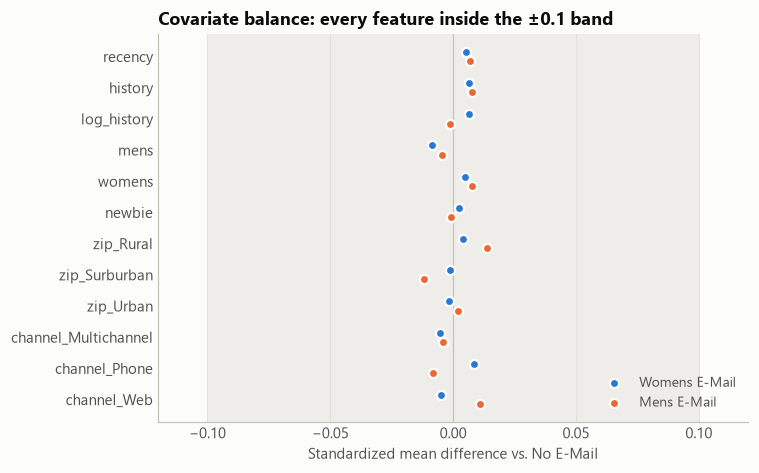

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.4))
ypos = np.arange(len(balance))
ax.axvspan(-0.1, 0.1, color=P.GRID, alpha=0.5, lw=0)
ax.axvline(0, color=P.AXIS, lw=0.8)
for off, label in zip([-0.15, 0.15], balance.columns):
    ax.scatter(balance[label], ypos + off, s=36, color=P.CAMPAIGN_COLORS[label], label=label,
               edgecolor=P.SURFACE, linewidth=1.5, zorder=3)
ax.set_yticks(ypos, balance.index); ax.invert_yaxis()
ax.set_xlim(-0.12, 0.12); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Standardized mean difference vs. No E-Mail")
ax.set_title("Covariate balance: every feature inside the ±0.1 band")
ax.legend(loc="lower right")
fig.tight_layout(); P.savefig(fig, "01_balance"); plt.show()

## 4 · Outcomes by arm

In [9]:
by_arm = df.groupby("segment")[config.OUTCOMES].agg(["mean"]).droplevel(1, axis=1).reindex(config.ARMS)
by_arm["n"] = counts
by_arm["spend_per_buyer"] = df[df.conversion == 1].groupby("segment")["spend"].mean()
by_arm

,visit,conversion,spend,n,spend_per_buyer
segment,,,,,
No E-Mail,0.1062,0.0057,0.6528,21306,114.0027
Mens E-Mail,0.1828,0.0125,1.4226,21307,113.5269
Womens E-Mail,0.1514,0.0088,1.0772,21387,121.8948


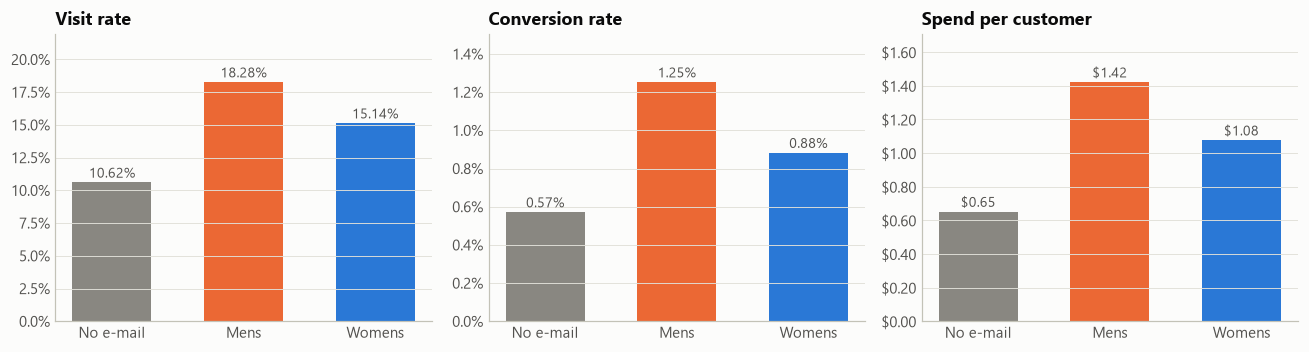

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
titles = {"visit": "Visit rate", "conversion": "Conversion rate", "spend": "Spend per customer"}
for ax, outcome in zip(axes, config.OUTCOMES):
    vals = by_arm[outcome]
    bars = ax.bar(range(3), vals, color=[P.CAMPAIGN_COLORS[a] for a in config.ARMS], width=0.6)
    ax.set_xticks(range(3), ["No e-mail", "Mens", "Womens"])
    ax.set_title(titles[outcome])
    fmt = (lambda v: f"${v:.2f}") if outcome == "spend" else (lambda v: f"{v:.2%}")
    for b, v in zip(bars, vals):
        ax.annotate(fmt(v), (b.get_x() + b.get_width() / 2, v), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=9, color=P.INK_2)
    if outcome == "spend":
        P.dollar(ax)
    else:
        P.percent(ax, "y", 1)
    ax.set_ylim(0, vals.max() * 1.2)
fig.tight_layout(); P.savefig(fig, "01_outcomes_by_arm"); plt.show()

## 5 · Average treatment effects

For each campaign versus the control and each outcome, four estimators are reported:

1. **Difference in means** with a Welch normal interval. This is the primary, design-based estimate.
2. **Percentile bootstrap** (2,000 draws, resampling within arm), as a check that does not rely on normality for a heavy-tailed outcome.
3. **Randomization-inference p-value** (2,000 permutations of the assignment) under the sharp null of no effect for anyone.
4. **Lin (2013) regression adjustment**: $Y \sim T + X_c + T \times X_c$ with HC2 errors. This uses covariates to improve precision without changing the estimand.

Six primary hypotheses (2 campaigns × 3 outcomes) are tested, so p-values are Holm-adjusted for family-wise error.

In [11]:
rows = []
for key, label in config.CAMPAIGNS.items():
    for outcome in config.OUTCOMES:
        Xc, t, y = data.campaign_arrays(df, key, outcome, X_all)
        dim = inference.diff_in_means(y, t)
        boot = inference.bootstrap_ate(y, t, n_boot=2000, seed=config.SEED)
        perm = inference.permutation_test(y, t, n_perm=2000, seed=config.SEED)
        lin = inference.lin_regression_ate(y, t, Xc)
        rows.append({
            "campaign": label, "outcome": outcome, "control_mean": dim["mean_c"],
            "treated_mean": dim["mean_t"], "ATE": dim["ate"], "ci_low": dim["ci_low"],
            "ci_high": dim["ci_high"], "rel_lift": dim["rel_lift"], "p_welch": dim["p_value"],
            "boot_low": boot["ci_low"], "boot_high": boot["ci_high"], "p_perm": perm["p_value"],
            "ATE_lin": lin["ate"], "se_dim": dim["se"], "se_lin": lin["se"],
        })
ate = pd.DataFrame(rows)
ate["p_holm"] = inference.holm(ate["p_welch"])
ate["var_reduction"] = 1 - (ate["se_lin"] / ate["se_dim"]) ** 2
ate.to_csv(config.ARTIFACTS_DIR / "ate_table.csv", index=False)
ate.set_index(["campaign", "outcome"])[["control_mean", "treated_mean", "ATE", "ci_low", "ci_high",
                                         "rel_lift", "p_holm", "boot_low", "boot_high", "p_perm",
                                         "ATE_lin", "var_reduction"]]

control_mean  treated_mean    ATE  ci_low  ci_high  rel_lift  p_holm  boot_low  boot_high  p_perm  ATE_lin  \
campaign      outcome                                                                                                                  
Womens E-Mail visit             0.1062        0.1514 0.0452  0.0389   0.0516    0.4261  0.0000    0.0391     0.0515  0.0005   0.0454   
              conversion        0.0057        0.0088 0.0031  0.0015   0.0047    0.5433  0.0003    0.0015     0.0048  0.0005   0.0031   
              spend             0.6528        1.0772 0.4244  0.1690   0.6799    0.6502  0.0011    0.1773     0.6881  0.0005   0.4256   
Mens E-Mail   visit             0.1062        0.1828 0.0766  0.0700   0.0832    0.7214  0.0000    0.0700     0.0832  0.0005   0.0761   
              conversion        0.0057        0.0125 0.0068  0.0050   0.0086    1.1884  0.0000    0.0051     0.0086  0.0005   0.0068   
              spend             0.6528        1.4226 0.7698  0.4851   1.0545    1.1793  0.0000    0.4996     1.0652  0.0005   0.7662   

                          var_reduction  
campaign      outcome                    
Womens E-Mail visit              0.0284  
              conversion         0.0019  
              spend              0.0006  
Mens E-Mail   visit              0.0293  
              conversion         0.0024  
              spend              0.0024

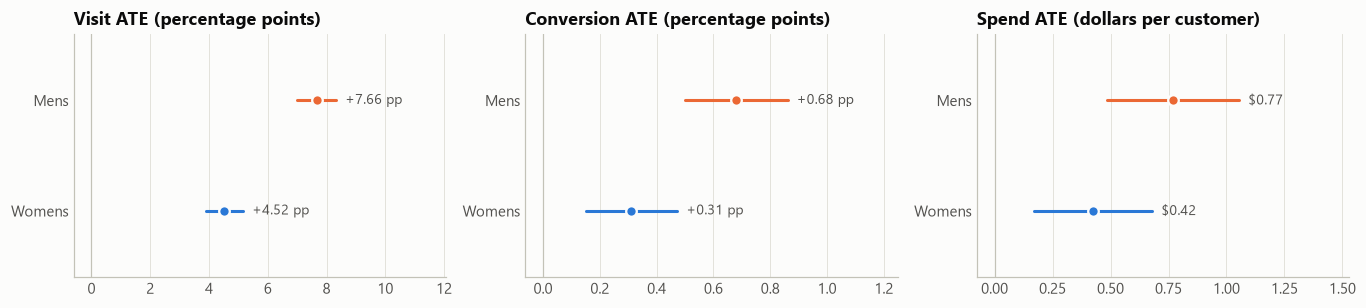

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 2.9))
units = {"visit": "pp", "conversion": "pp", "spend": "$"}
for ax, outcome in zip(axes, config.OUTCOMES):
    sub = ate[ate.outcome == outcome].reset_index(drop=True)
    scale = 100 if units[outcome] == "pp" else 1
    for i, r in sub.iterrows():
        c = P.CAMPAIGN_COLORS[r.campaign]
        ax.plot([r.ci_low * scale, r.ci_high * scale], [i, i], color=c, lw=2, solid_capstyle="round")
        ax.scatter(r.ATE * scale, i, color=c, s=48, zorder=3, edgecolor=P.SURFACE, linewidth=1.5)
        txt = f"${r.ATE:.2f}" if outcome == "spend" else f"{r.ATE * 100:+.2f} pp"
        ax.annotate(txt, (r.ci_high * scale, i), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=9, color=P.INK_2)
    ax.axvline(0, color=P.AXIS, lw=0.8)
    ax.set_yticks(range(len(sub)), [c.replace(" E-Mail", "") for c in sub.campaign])
    ax.set_ylim(-0.6, len(sub) - 0.4)
    ax.grid(axis="y", visible=False); ax.grid(axis="x")
    ax.set_title(f"{outcome.capitalize()} ATE ({'percentage points' if scale == 100 else 'dollars per customer'})")
    xmax = (sub.ci_high.max() * scale) * 1.45
    ax.set_xlim(min(0, sub.ci_low.min() * scale) - 0.05 * xmax, xmax)
fig.tight_layout(); P.savefig(fig, "01_ate_forest"); plt.show()

In [13]:
def fmt_row(r):
    if r.outcome == "spend":
        return f"**${r.ATE:.3f}** per customer (95% CI ${r.ci_low:.3f} to ${r.ci_high:.3f}; {r.rel_lift:+.0%} relative)"
    return (f"**{r.ATE * 100:+.2f} pp** (95% CI {r.ci_low * 100:+.2f} to {r.ci_high * 100:+.2f}; "
            f"{r.rel_lift:+.0%} relative)")

lines = []
for label in config.CAMPAIGNS.values():
    lines.append(f"**{label}** vs. no e-mail:")
    for _, r in ate[ate.campaign == label].iterrows():
        lines.append(f"* {r.outcome}: {fmt_row(r)}, Holm p = {r.p_holm:.1e}")
display(Markdown("\n".join(lines)))

**Womens E-Mail** vs. no e-mail:
* visit: **+4.52 pp** (95% CI +3.89 to +5.16; +43% relative), Holm p = 9.7e-44
* conversion: **+0.31 pp** (95% CI +0.15 to +0.47; +54% relative), Holm p = 3.1e-04
* spend: **$0.424** per customer (95% CI $0.169 to $0.680; +65% relative), Holm p = 1.1e-03
**Mens E-Mail** vs. no e-mail:
* visit: **+7.66 pp** (95% CI +7.00 to +8.32; +72% relative), Holm p = 1.6e-112
* conversion: **+0.68 pp** (95% CI +0.50 to +0.86; +119% relative), Holm p = 5.9e-13
* spend: **$0.770** per customer (95% CI $0.485 to $1.055; +118% relative), Holm p = 3.5e-07

**Reading the effects**

* Both campaigns causally increase visits, conversions and spend. All six effects survive the Holm correction, and the bootstrap and permutation results agree with the Welch analysis.
* The **Men's e-mail** has the larger average effect on every outcome. The Women's e-mail is still clearly positive.
* Regression adjustment barely moves the estimates and cuts variance by at most ~3% (visit), with almost no gain for spend. The pre-treatment features explain very little of the outcome variance, which is a first hint that **customer-level heterogeneity will be hard to estimate**.
* Relative lifts are large (+65% and +118% spend), but on a small base: the absolute effects are \$0.42 and \$0.77 per customer mailed.

### 5b · Head-to-head: Men's vs. Women's e-mail

In [14]:
m = df["segment"].isin(list(config.CAMPAIGNS.values()))
h2h = []
for outcome in config.OUTCOMES:
    r = inference.diff_in_means(df.loc[m, outcome], (df.loc[m, "segment"] == "Mens E-Mail").astype(int))
    h2h.append({"outcome": outcome, "mens_minus_womens": r["ate"], "ci_low": r["ci_low"],
                "ci_high": r["ci_high"], "p_value": r["p_value"]})
pd.DataFrame(h2h).set_index("outcome")

,mens_minus_womens,ci_low,ci_high,p_value
outcome,,,,
visit,0.0314,0.0243,0.0384,0.0000
conversion,0.0037,0.0017,0.0056,0.0002
spend,0.3454,0.0326,0.6583,0.0305


### 5c · Where does the spend effect come from?

Spend per customer = conversion rate × spend per buyer. The conversion effect is causal. The **spend per buyer** comparison is descriptive only, because it conditions on a post-treatment variable (who buys), so its arms are no longer randomized.

In [15]:
decomp = by_arm[["conversion", "spend_per_buyer", "spend"]].copy()
decomp["conversion_x_aov"] = decomp["conversion"] * decomp["spend_per_buyer"]
decomp

,conversion,spend_per_buyer,spend,conversion_x_aov
segment,,,,
No E-Mail,0.0057,114.0027,0.6528,0.6528
Mens E-Mail,0.0125,113.5269,1.4226,1.4226
Womens E-Mail,0.0088,121.8948,1.0772,1.0772


The extra spend comes almost entirely from **more customers buying**, not larger baskets. Spend per buyer is similar across arms. This matters for modelling: the incremental-spend signal is carried by a few hundred extra purchases.

## 6 · Precision and minimum detectable effects

The table shows the smallest true effect detectable with 80% power at α = 0.05 (two-sided), using the full arms and the 20% held-out test partition used for final policy evaluation in notebook 04.

In [16]:
mde_rows = []
for key, label in config.CAMPAIGNS.items():
    for outcome in config.OUTCOMES:
        _, t, y = data.campaign_arrays(df, key, outcome, X_all)
        sd1, sd0 = y[t == 1].std(), y[t == 0].std()
        n1, n0 = (t == 1).sum(), (t == 0).sum()
        mde_rows.append({"campaign": label, "outcome": outcome,
                         "ATE": ate.query("campaign == @label and outcome == @outcome").ATE.item(),
                         "MDE_full": inference.minimum_detectable_effect(sd1, sd0, n1, n0),
                         "MDE_test_20pct": inference.minimum_detectable_effect(sd1, sd0, 0.2 * n1, 0.2 * n0)})
mde = pd.DataFrame(mde_rows)
mde["ATE_over_MDE_test"] = mde["ATE"] / mde["MDE_test_20pct"]
mde.set_index(["campaign", "outcome"])

ATE  MDE_full  MDE_test_20pct  ATE_over_MDE_test
campaign      outcome                                                       
Womens E-Mail visit      0.0452    0.0091          0.0203             2.2324
              conversion 0.0031    0.0023          0.0052             0.6037
              spend      0.4244    0.3651          0.8165             0.5198
Mens E-Mail   visit      0.0766    0.0095          0.0212             3.6109
              conversion 0.0068    0.0026          0.0058             1.1796
              spend      0.7698    0.4069          0.9099             0.8461

On the 20% test partition, the spend MDE (≈ \$0.82) is about **twice** the Women's campaign's whole average effect. Even on the full data, the spend effects are only 1.2–1.9× their MDE. **Comparing targeting policies on spend will therefore carry wide intervals.** This is why later notebooks use variance-reducing doubly robust (AIPW) evaluation, cross-fitting over the development data for model selection, and repeated splits for robustness.

## 7 · Is there heterogeneity worth modelling?

The cells below give descriptive treatment effects within single pre-treatment segments, without models. Each family of segment tests is Holm-adjusted. These are **observed experimental estimates for subgroups**. They are valid causal effects *for that subgroup*, but many comparisons are made, so individual significant cells should be read with caution.

In [17]:
seg = df.copy()
seg["recency_bucket"] = pd.cut(seg["recency"], [0, 3, 6, 9, 12], labels=["1-3 mo", "4-6 mo", "7-9 mo", "10-12 mo"])
seg["merch_history"] = np.select([(seg.mens == 1) & (seg.womens == 1), seg.mens == 1, seg.womens == 1],
                                 ["both", "mens only", "womens only"], "neither")
seg["newbie"] = seg["newbie"].map({1: "new", 0: "existing"})
seg_vars = ["merch_history", "channel", "newbie", "zip_code", "recency_bucket", "history_segment"]

seg_results = []
for key, label in config.CAMPAIGNS.items():
    sub = seg[seg["segment"].isin([label, config.CONTROL])]
    t = (sub["segment"] == label).astype(int).to_numpy()
    for outcome in ["visit", "spend"]:
        for v in seg_vars:
            r = inference.segment_effects(sub, t, outcome, v)
            r["campaign"], r["outcome"] = label, outcome
            seg_results.append(r)
seg_results = pd.concat(seg_results, ignore_index=True)
seg_results.to_csv(config.ARTIFACTS_DIR / "segment_effects.csv", index=False)
seg_results.query("outcome == 'spend'").set_index(["campaign", "variable", "level"])[
    ["n", "mean_c", "ate", "ci_low", "ci_high", "p_value", "p_holm"]]

n  mean_c     ate  ci_low  ci_high  p_value  p_holm
campaign      variable        level                                                                    
Womens E-Mail merch_history   both               4267  1.1801  0.1619 -0.8133   1.1371   0.7449  0.7449
                              mens only         19260  0.6954  0.2784 -0.1236   0.6803   0.1747  0.3493
                              womens only       19166  0.4906  0.6316  0.2951   0.9682   0.0002  0.0007
              channel         Multichannel       5185  0.6157  1.1575  0.2589   2.0562   0.0116  0.0348
                              Phone             18781  0.6445  0.2325 -0.1192   0.5841   0.1951  0.1951
                              Web               18727  0.6714  0.4163  0.0246   0.8081   0.0373  0.0745
              newbie          existing          21235  0.9354  0.1140 -0.2755   0.5034   0.5663  0.5663
                              new               21458  0.3724  0.7323  0.4012   1.0634   0.0000  0.0000
              zip_code        Rural              6320  0.7671  0.5148 -0.1195   1.1492   0.1117  0.2234
                              Surburban         19275  0.6694  0.1772 -0.1936   0.5479   0.3490  0.3490
                              Urban             17098  0.5920  0.6691  0.2483   1.0900   0.0018  0.0055
              recency_bucket  1-3 mo            14924  0.9436  0.3586 -0.1154   0.8326   0.1382  0.2763
                              4-6 mo             9519  0.5192  0.6655  0.1098   1.2211   0.0189  0.0756
                              7-9 mo             9326  0.5759  0.2995 -0.2485   0.8474   0.2841  0.2841
                              10-12 mo           8924  0.3882  0.4100 -0.0218   0.8418   0.0627  0.1882
              history_segment 1) $0 - $100      15246  0.5169  0.6258  0.1881   1.0635   0.0051  0.0355
                              2) $100 - $200     9563  0.4229  0.4584  0.0439   0.8729   0.0302  0.1510
                              3) $200 - $350     8199  0.9329 -0.3231 -0.8907   0.2444   0.2645  0.7934
                              4) $350 - $500     4312  1.0103 -0.1009 -0.8682   0.6664   0.7966  0.7966
                              5) $500 - $750     3314  0.5389  1.2857  0.2863   2.2850   0.0117  0.0701
                              6) $750 - $1,000   1215  0.3495  0.6483 -0.3172   1.6137   0.1881  0.7526
                              7) $1,000 +         844  2.1698  2.5068 -1.9187   6.9323   0.2669  0.7934
Mens E-Mail   merch_history   both               4330  1.1801  1.8250  0.4902   3.1598   0.0074  0.0074
                              mens only         19196  0.6954  0.6827  0.2472   1.1183   0.0021  0.0042
                              womens only       19087  0.4906  0.6157  0.2697   0.9618   0.0005  0.0015
              channel         Multichannel       5183  0.6157  1.2091  0.3911   2.0272   0.0038  0.0075
                              Phone             18567  0.6445  0.5641  0.1612   0.9670   0.0061  0.0075
                              Web               18863  0.6714  0.8504  0.3972   1.3037   0.0002  0.0007
              newbie          existing          21232  0.9354  0.5780  0.1416   1.0143   0.0094  0.0094
                              new               21381  0.3724  0.9600  0.5938   1.3262   0.0000  0.0000
              zip_code        Rural              6382  0.7671  0.7555  0.0509   1.4601   0.0356  0.0356
                              Surburban         19126  0.6694  0.8038  0.3542   1.2535   0.0005  0.0014
                              Urban             17105  0.5920  0.7365  0.3110   1.1620   0.0007  0.0014
              recency_bucket  1-3 mo            14907  0.9436  1.0476  0.4642   1.6310   0.0004  0.0017
                              4-6 mo             9439  0.5192  0.4884  0.0089   0.9679   0.0459  0.0567
                              7-9 mo             9387  0.5759  0.6051  0.0642   1.1460   0.0283  0.0567
                              10-12 mo           8880  0.3882  0.7721  0.2095   1.3347   0.0072  0.0

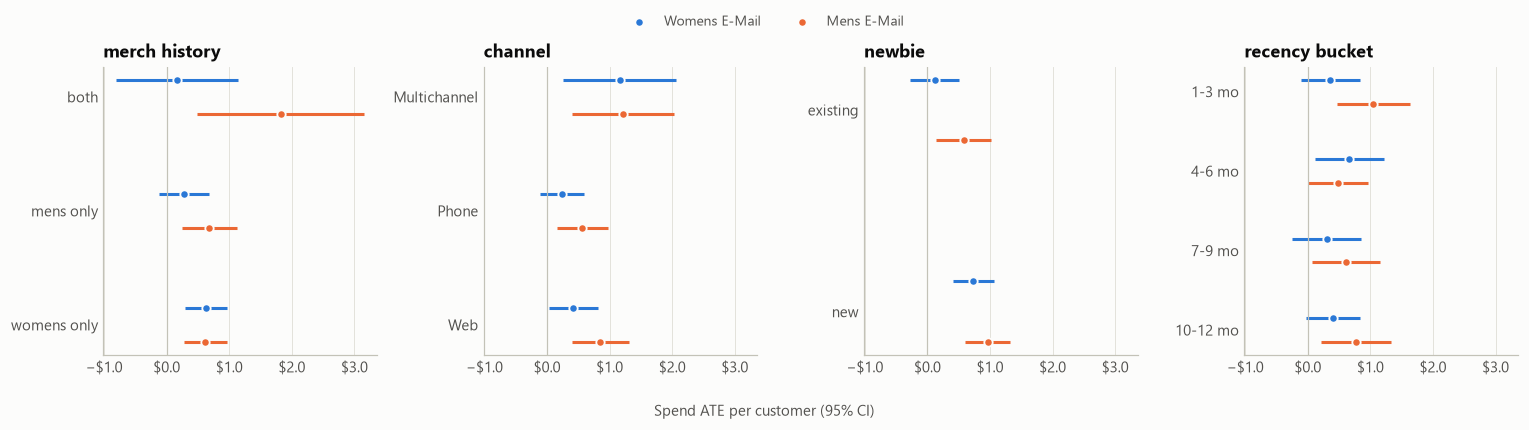

In [18]:
plot_vars = ["merch_history", "channel", "newbie", "recency_bucket"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharex=True)
for ax, v in zip(axes, plot_vars):
    sub = seg_results.query("outcome == 'spend' and variable == @v")
    levels = list(dict.fromkeys(sub["level"]))
    for off, label in zip([-0.15, 0.15], config.CAMPAIGNS.values()):
        s = sub[sub.campaign == label].set_index("level").reindex(levels)
        y = np.arange(len(levels)) + off
        c = P.CAMPAIGN_COLORS[label]
        ax.hlines(y, s.ci_low, s.ci_high, color=c, lw=2)
        ax.scatter(s.ate, y, color=c, s=30, zorder=3, edgecolor=P.SURFACE, linewidth=1.2,
                   label=label if v == plot_vars[0] else None)
    ax.axvline(0, color=P.AXIS, lw=0.8)
    ax.set_yticks(range(len(levels)), levels); ax.invert_yaxis()
    ax.grid(axis="y", visible=False); ax.grid(axis="x")
    ax.set_title(v.replace("_", " ")); P.dollar(ax, "x", 1)
fig.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.06))
fig.supxlabel("Spend ATE per customer (95% CI)", fontsize=10, color=P.INK_2)
fig.tight_layout(); P.savefig(fig, "01_segment_effects"); plt.show()

In [19]:
sig = seg_results[(seg_results.p_holm < 0.05)]
display(Markdown(
    f"**{len(sig)} of {len(seg_results)}** segment-level effects are significant after Holm adjustment within their family. "
    "Effects are positive almost everywhere, and intervals overlap heavily between levels of the same variable."))
sig.groupby(["campaign", "outcome"]).size().rename("significant segments").to_frame()

**63 of 88** segment-level effects are significant after Holm adjustment within their family. Effects are positive almost everywhere, and intervals overlap heavily between levels of the same variable.

significant segments
campaign      outcome                      
Mens E-Mail   spend                      14
              visit                      22
Womens E-Mail spend                       5
              visit                      22

In [20]:
from scipy import stats
# Formal test of heterogeneity: Lin interaction terms jointly zero?
import statsmodels.api as sm
het_rows = []
for key, label in config.CAMPAIGNS.items():
    for outcome in ["visit", "spend"]:
        Xc, t, y = data.campaign_arrays(df, key, outcome, X_all)
        Xc = Xc.drop(columns=["history", "zip_Urban", "channel_Web"])  # drop collinear columns
        Xc = Xc - Xc.mean()
        design = sm.add_constant(pd.concat([pd.Series(t, index=Xc.index, name="T"), Xc,
                                            Xc.mul(t, axis=0).add_prefix("Tx_")], axis=1))
        fit = sm.OLS(y, design).fit(cov_type="HC2")
        names = [c for c in design.columns if c.startswith("Tx_")]
        w = fit.wald_test(" = 0, ".join(names) + " = 0", scalar=True)
        het_rows.append({"campaign": label, "outcome": outcome, "wald_chi2": float(w.statistic),
                         "df": len(names), "p_value": float(w.pvalue)})
pd.DataFrame(het_rows).set_index(["campaign", "outcome"])

wald_chi2  df  p_value
campaign      outcome                        
Womens E-Mail visit     106.5240   9   0.0000
              spend      20.6898   9   0.0141
Mens E-Mail   visit      27.1296   9   0.0013
              spend       7.6017   9   0.5747

The joint Wald test asks whether treatment × covariate interactions are jointly zero, which is a linear test for any effect heterogeneity. It separates two cases:

* **Visit:** heterogeneity is detected for both campaigns, overwhelmingly for the Women's e-mail. Customer features predict who is moved to visit.
* **Spend:** there is moderate evidence for the Women's e-mail (p ≈ 0.01) and **none for the Men's e-mail** (p ≈ 0.57). The outcome is rare and noisy, so any spend uplift model is fitting a small signal.

The segment chart shows the same pattern. The Women's e-mail barely moves existing customers, phone-only buyers, or customers who bought only men's merchandise. Its effect is concentrated among new customers and women's-merchandise buyers. The Men's e-mail lifts spend fairly uniformly.

## 8 · Summary and decisions carried forward

| Decision | Choice | Reason |
|---|---|---|
| Validity | Randomization accepted | SRM p = 0.90, all \|SMD\| < 0.02, assignment AUC ≈ 0.50 |
| Treatment arms | Both campaigns modelled, each vs. no e-mail; **Women's e-mail is the primary arm**, Men's is a replication and the alternative in campaign selection | Women's has the smaller average effect and the only detectable spend heterogeneity, so targeting has the most room to change the decision |
| Primary outcome | **Spend** (dollars), with visit as a secondary, higher-signal outcome | Spend maps directly to contribution: incremental profit = margin × incremental spend − cost |
| Propensities | Empirical arm shares (≈ 1/3 each) used as the **known** assignment probabilities | Verified by the SRM test |
| Evaluation | AIPW policy values, cross-fitting, Holm for families of tests | Spend MDE on a 20% split ≈ the size of the effect itself |

In [21]:
summary = {
    "n_customers": len(df), "arms": counts.to_dict(), "srm_p": srm["p_value"],
    "max_abs_smd": float(balance.abs().max().max()),
}
pd.Series(summary)

n_customers                                                64000
arms           {'No E-Mail': 21306, 'Mens E-Mail': 21307, 'Wo...
srm_p                                                     0.9037
max_abs_smd                                               0.0137
dtype: object